<a href="https://colab.research.google.com/github/dldustj0715/machine_learning/blob/main/week10/%EC%A3%BC%EA%B0%80_RNN_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 삼성전자 주가 예측: SimpleRNN vs LSTM
삼성전자 **시가(Open)** 를 예측한다.

In [1]:
!pip -q install finance-datareader

In [2]:
import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)
WINDOW_SIZE = 30
TEST_SIZE = 200
EPOCHS = 50
BATCH_SIZE = 8

## 1. 주가 데이터 불러오기 및 Open 열 확인

In [3]:
df = fdr.DataReader('005930', '2016')
print('전체 데이터:', df.shape)
print(df.head())
open_values = df[['Open']].dropna()
print('\n시가(Open) 데이터:')
print(open_values.head())

전체 데이터: (2660, 6)
             Open   High    Low  Close  Volume    Change
Date                                                    
2016-01-04  25200  25200  24100  24100  306939 -0.043651
2016-01-05  24040  24360  23720  24160  216002  0.002490
2016-01-06  24160  24160  23360  23500  366752 -0.027318
2016-01-07  23320  23660  23020  23260  282388 -0.010213
2016-01-08  23260  23720  23260  23420  257763  0.006879

시가(Open) 데이터:
             Open
Date             
2016-01-04  25200
2016-01-05  24040
2016-01-06  24160
2016-01-07  23320
2016-01-08  23260


## 2. 학습/테스트 분리 및 정규화
테스트 데이터의 정보를 학습 시 사용하지 않도록 학습 구간에서만 scaler를 학습합니다.

In [4]:
train_raw = open_values.iloc[:-TEST_SIZE]
test_raw = open_values.iloc[-TEST_SIZE:]
scaler = MinMaxScaler()
train_data = scaler.fit_transform(train_raw)
test_data = scaler.transform(test_raw)
print('Train:', train_data.shape, 'Test:', test_data.shape)
print('정규화 전 Open:', train_raw.head().T.to_numpy())
print('정규화 후 Open:', train_data[:5].T)

Train: (2460, 1) Test: (200, 1)
정규화 전 Open: [[25200 24040 24160 23320 23260]]
정규화 후 Open: [[0.17560976 0.16752613 0.16836237 0.16250871 0.16209059]]


## 3. Window Size에 맞춰 시퀀스 생성

In [5]:
def make_sample(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i:i+window])
        y.append(data[i+window])
    return np.array(X), np.array(y)

X_train, y_train = make_sample(train_data, WINDOW_SIZE)
# 테스트 첫날을 예측하기 위해 학습 구간의 마지막 WINDOW_SIZE일 포함
test_input = np.concatenate([train_data[-WINDOW_SIZE:], test_data], axis=0)
X_test, y_test = make_sample(test_input, WINDOW_SIZE)
print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_test:', X_test.shape, 'y_test:', y_test.shape)
print('첫 입력 샘플 (앞 5개):', X_train[0, :5, 0])
print('첫 정답:', y_train[0, 0])

X_train: (2430, 30, 1) y_train: (2430, 1)
X_test: (200, 30, 1) y_test: (200, 1)
첫 입력 샘플 (앞 5개): [0.17560976 0.16752613 0.16836237 0.16250871 0.16209059]
첫 정답: 0.16766550522648083


## 4. SimpleRNN 모델 구성 및 학습

In [6]:
rnn_model = tf.keras.Sequential([
    tf.keras.Input(shape=(WINDOW_SIZE, 1)),
    tf.keras.layers.SimpleRNN(64, return_sequences=True),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(1)
])
rnn_model.compile(optimizer='adam', loss='mse')
rnn_model.summary()
rnn_history = rnn_model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1, shuffle=False)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 30, 64)         │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,361 (28.75 KB)

 Trainable params: 7,361 (28.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.0027
Epoch 2/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0031
Epoch 3/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0040
Epoch 4/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0025
Epoch 5/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0012
Epoch 6/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 5.3201e-04
Epoch 7/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 3.0340e-04
Epoch 8/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 2.5879e-04
Epoch 9/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2.7423e-04
Epoch 10/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2.8761e-04
Epoch 11/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2.9721e-04
Epoch 12/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 3.0625e-04
Epoch 13/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 3.1567e-04
Epoch 14/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.2292e-04
Epoch 15/50
304/304 

## 5. LSTM 모델 구성 및 학습

In [7]:
lstm_model = tf.keras.Sequential([
    tf.keras.Input(shape=(WINDOW_SIZE, 1)),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.summary()
lstm_history = lstm_model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1, shuffle=False)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 8.0682e-04
Epoch 2/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.8604e-04
Epoch 3/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 6.5984e-04
Epoch 4/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 5.6783e-04
Epoch 5/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 4.8673e-04
Epoch 6/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 4.2633e-04
Epoch 7/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.7869e-04
Epoch 8/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.4068e-04
Epoch 9/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.1432e-04
Epoch 10/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.9697e-04
Epoch 11/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2.8357e-04
Epoch 12/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2.7187e-04
Epoch 13/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 2.6114e-04
Epoch 14/50
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2.5113e-04
E

## 6. 테스트 구간 예측 및 원화 단위 복원

In [8]:
rnn_pred = scaler.inverse_transform(rnn_model.predict(X_test))
lstm_pred = scaler.inverse_transform(lstm_model.predict(X_test))
actual = scaler.inverse_transform(y_test)
print(pd.DataFrame({'Actual_Open':actual.ravel(), 'RNN_Pred':rnn_pred.ravel(), 'LSTM_Pred':lstm_pred.ravel()}, index=test_raw.index).head(10))

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
            Actual_Open       RNN_Pred      LSTM_Pred
Date                                                 
2026-01-14     137000.0  143534.453125  141397.312500
2026-01-15     139000.0  136854.187500  138476.640625
2026-01-16     145300.0  141310.671875  139151.125000
2026-01-19     147200.0  146988.968750  144829.828125
2026-01-20     148500.0  146789.515625  148003.562500
2026-01-21     141900.0  147774.265625  149421.531250
2026-01-22     155000.0  141229.281250  143846.359375
2026-01-23     154700.0  154929.953125  152573.546875
2026-01-26     154900.0  152221.796875  155571.671875
2026-01-27     150500.0  153063.468750  155682.875000


## 7. 평가 지표 출력 (원화 기준)

In [9]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE (KRW)': mean_absolute_error(y_true, y_pred), 'MSE (KRW^2)': mse, 'RMSE (KRW)': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}

results = pd.DataFrame({'SimpleRNN': metrics(actual, rnn_pred), 'LSTM': metrics(actual, lstm_pred)}).T
print(results.round(4))

            MAE (KRW)   MSE (KRW^2)  RMSE (KRW)      R2
SimpleRNN  39041.6984  2.329242e+09  48262.2233  0.1846
LSTM       11783.6498  2.386388e+08  15447.9386  0.9165


## 8. 실제 주가와 예측 주가 비교

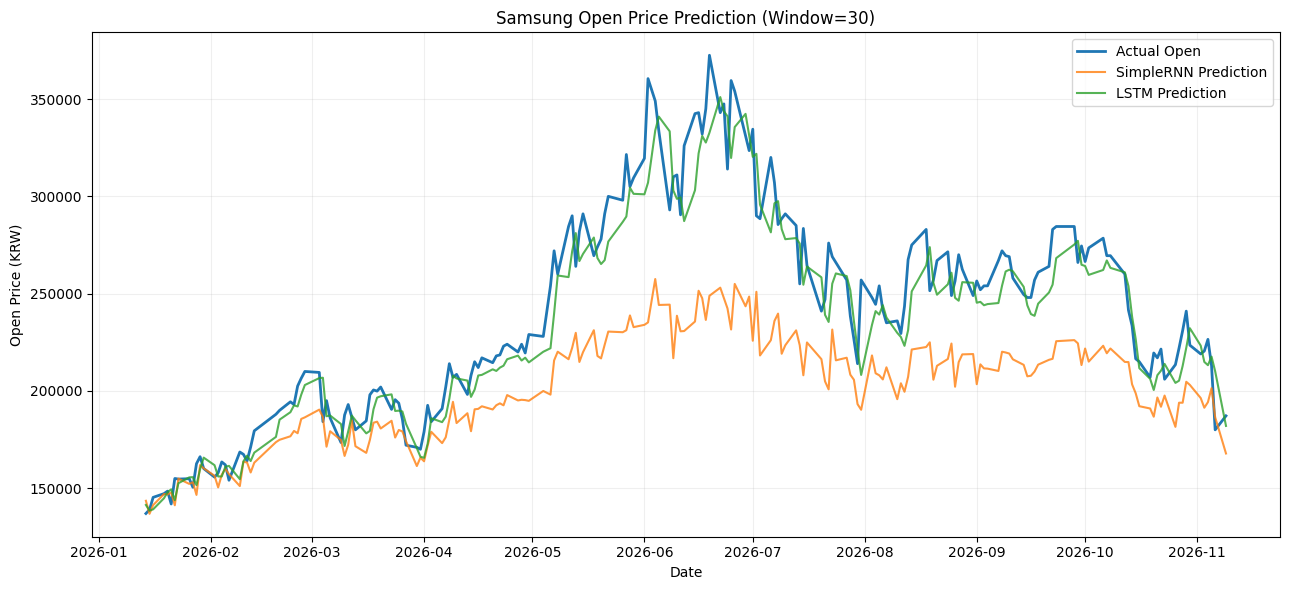

In [10]:
plt.figure(figsize=(13, 6))
plt.plot(test_raw.index, actual.ravel(), label='Actual Open', linewidth=2)
plt.plot(test_raw.index, rnn_pred.ravel(), label='SimpleRNN Prediction', alpha=.8)
plt.plot(test_raw.index, lstm_pred.ravel(), label='LSTM Prediction', alpha=.8)
plt.title(f'Samsung Open Price Prediction (Window={WINDOW_SIZE})')
plt.xlabel('Date'); plt.ylabel('Open Price (KRW)'); plt.legend(); plt.grid(alpha=.2)
plt.tight_layout(); plt.show()